Construct distrubution of turnaround times for same icao and for ladd-> ladd, pia->pia (should be same) pia->ladd, ladd->pia 

I will produce function that uses the (what shoudl be gaussian disturbution) to create probablity.

In [1]:
from pia.ground_truth import get_ground_truth_mappings
df_groundtruth = get_ground_truth_mappings()

# Divide into flight transition categories

In [ ]:
from datetime import date
import polars as pl
from data_engineering.flights.flight_type import get_flights
from data_engineering.filters import pia_or_american_ladd
start_dt = date(2026, 1, 1)
end_dt = date(2026,7,1)
df_flights = get_flights(start_dt, end_dt)
df_flights = df_flights.filter(pia_or_american_ladd())

Loading airports from /Volumes/T2-SSD/planequery/data/raw/ourairports/airports.csv


In [5]:
pia_icaos = df_groundtruth.get_column("pia_icao").to_list()
real_icaos = df_groundtruth.get_column("real_icao").to_list()
real_to_pia_icaos: dict[str, set[str]] = dict()
for pia_icao, real_icao in zip(pia_icaos, real_icaos):
    real_to_pia_icaos.setdefault(real_icao, set()).add(pia_icao)

In [11]:
import polars as pl

from data_engineering.flights.flight_type import Flight, flights_df_to_flights

pia_to_pia_times = []
real_to_real_times = []
pia_to_real_times = []
real_to_pia_times = []

def process(flights: list[Flight]):
    turnaround_times = []
    if len(flights) < 2:
        return turnaround_times
    for f_0, f_1 in zip(flights, flights[1:]):
        turnaround_time = f_1.takeoff_time - f_0.landing_time
        if f_0.icao in pia_icaos and f_1.icao in pia_icaos:
            pia_to_pia_times.append(turnaround_time)
        elif f_0.icao not in pia_icaos and f_1.icao not in pia_icaos:
            real_to_real_times.append(turnaround_time)
        elif f_0.icao in pia_icaos and f_1.icao not in pia_icaos:
            pia_to_real_times.append(turnaround_time)
        elif f_0.icao not in pia_icaos and f_1.icao in pia_icaos:
            real_to_pia_times.append(turnaround_time)
for real_icao, pia_icaos in real_to_pia_icaos.items():
    icaos = list(pia_icaos) + [real_icao]
    df = df_flights.filter(pl.col("icao").is_in(icaos)).sort("takeoff_time")
    flights = flights_df_to_flights(df)
    process(flights)

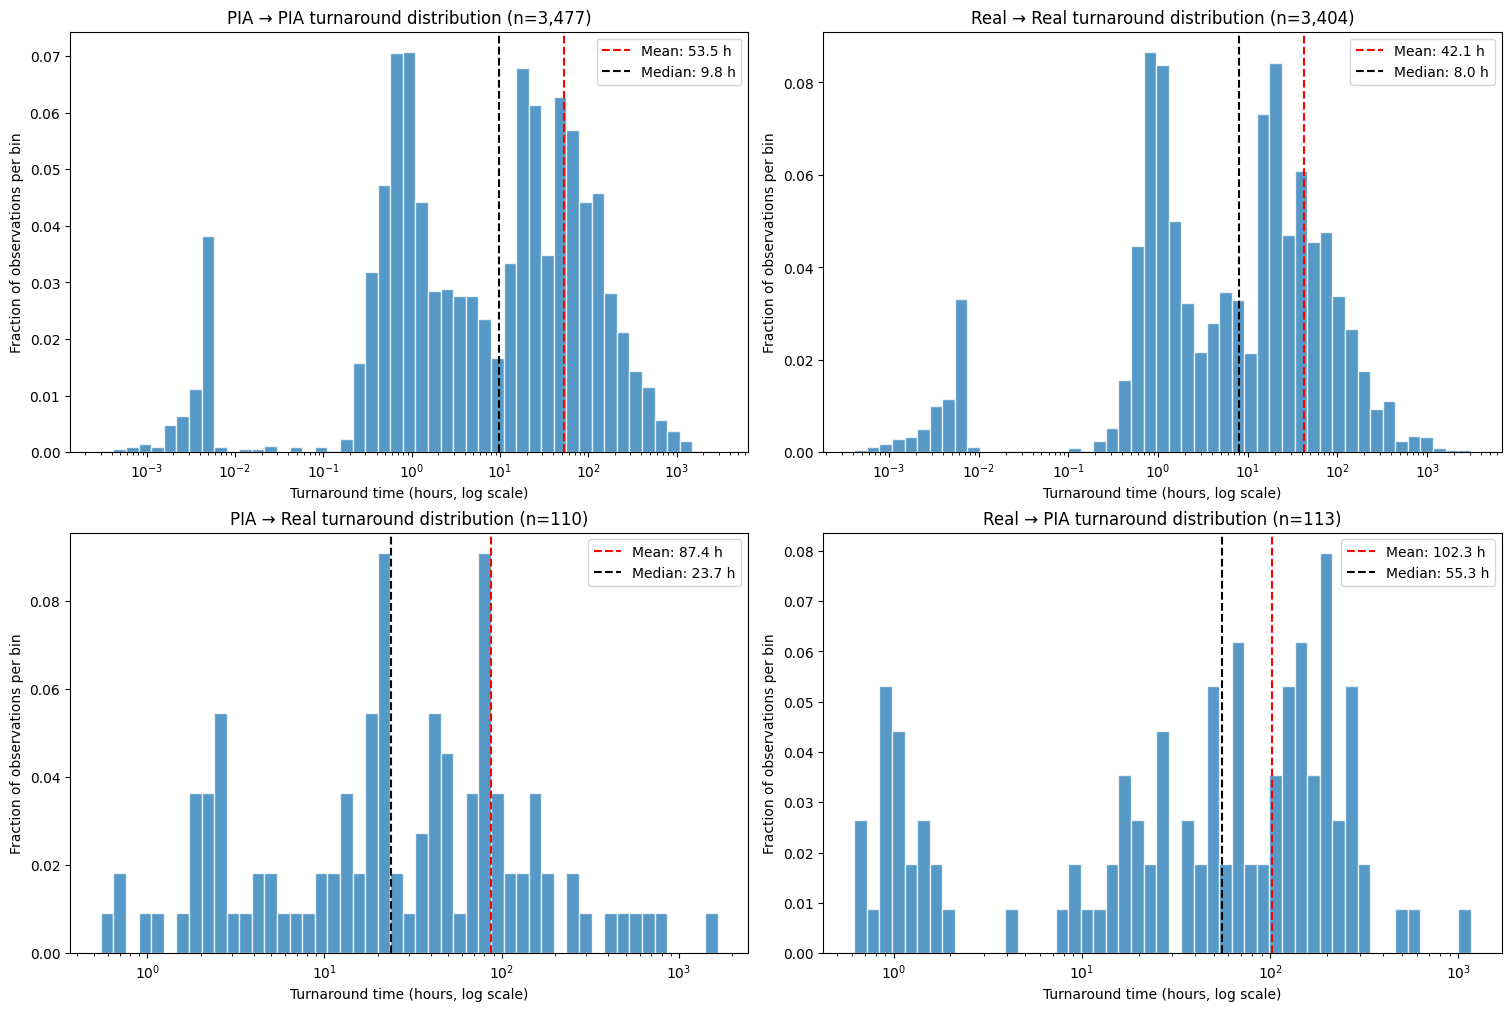

In [14]:
import numpy as np

import matplotlib.pyplot as plt

turnaround_groups = {
    "PIA → PIA": pia_to_pia_times,
    "Real → Real": real_to_real_times,
    "PIA → Real": pia_to_real_times,
    "Real → PIA": real_to_pia_times,
}

turnaround_hours = {
    name: np.array([duration.total_seconds() / 3600 for duration in durations])
    for name, durations in turnaround_groups.items()
}

turnaround_stats = pl.DataFrame(
    [
        {
            "transition": name,
            "count": len(values),
            "mean_hours": values.mean(),
            "median_hours": np.median(values),
            "std_hours": values.std(ddof=1),
            "min_hours": values.min(),
            "p05_hours": np.percentile(values, 5),
            "p25_hours": np.percentile(values, 25),
            "p75_hours": np.percentile(values, 75),
            "p95_hours": np.percentile(values, 95),
            "max_hours": values.max(),
        }
        for name, values in turnaround_hours.items()
        if len(values) > 0
    ]
).sort("transition")

turnaround_stats

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

for ax, (name, values) in zip(axes.flat, turnaround_hours.items()):
    plotted = values[np.isfinite(values) & (values > 0)]
    bins = np.geomspace(plotted.min(), plotted.max(), 50)

    ax.hist(
        plotted,
        bins=bins,
        weights=np.ones(len(plotted)) / len(plotted),
        alpha=0.75,
        edgecolor="white",
    )

    mean = plotted.mean()
    median = np.median(plotted)

    ax.axvline(mean, color="red", linestyle="--",
               label=f"Mean: {mean:.1f} h")
    ax.axvline(median, color="black", linestyle="--",
               label=f"Median: {median:.1f} h")

    ax.set_xscale("log")
    ax.set_title(f"{name} turnaround distribution (n={len(plotted):,})")
    ax.set_xlabel("Turnaround time (hours, log scale)")
    ax.set_ylabel("Fraction of observations per bin")
    ax.legend()

plt.show()

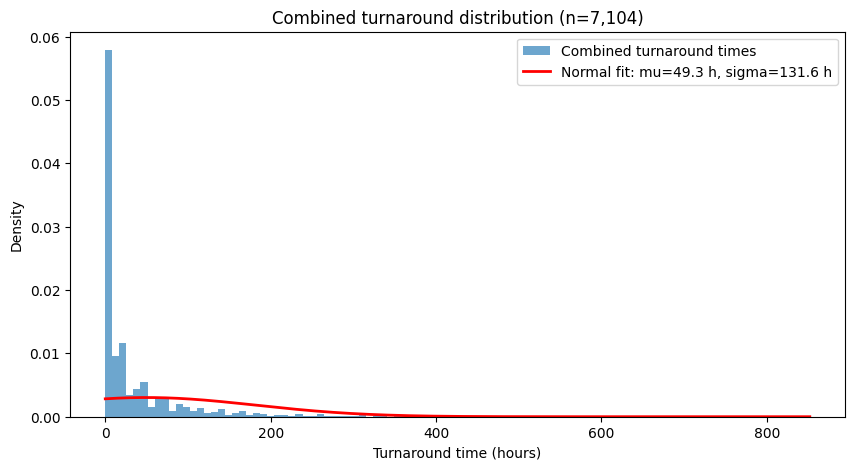

(np.float64(49.30544848270145), np.float64(131.62431669239325))

In [15]:
from scipy.stats import norm

# Combine all four transition types and retain valid turnaround times.
combined_turnaround_hours = np.concatenate(list(turnaround_hours.values()))
combined_turnaround_hours = combined_turnaround_hours[
    np.isfinite(combined_turnaround_hours) & (combined_turnaround_hours > 0)
]

# Maximum-likelihood fit of Normal(mu, sigma).
normal_mu, normal_sigma = norm.fit(combined_turnaround_hours)

def combined_turnaround_pdf(hours):
    """Density under the fitted normal turnaround-time distribution."""
    return norm.pdf(hours, loc=normal_mu, scale=normal_sigma)

x = np.linspace(0, np.percentile(combined_turnaround_hours, 99.5), 1_000)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(
    combined_turnaround_hours,
    bins=100,
    range=(0, x.max()),
    density=True,
    alpha=0.65,
    label="Combined turnaround times",
)
ax.plot(
    x,
    combined_turnaround_pdf(x),
    color="red",
    linewidth=2,
    label=f"Normal fit: mu={normal_mu:.1f} h, sigma={normal_sigma:.1f} h",
)
ax.set(
    title=f"Combined turnaround distribution (n={len(combined_turnaround_hours):,})",
    xlabel="Turnaround time (hours)",
    ylabel="Density",
)
ax.legend()
plt.show()

normal_mu, normal_sigma

In [17]:
normal_sigma

np.float64(131.62431669239325)

In [18]:
hours = 5
NORMAL_MU = 49.30
NORMAL_SIGMA = 131.62
norm.pdf(hours, loc=normal_mu, scale=normal_sigma)

np.float64(0.0028639832128293037)